### SEMMA · Fase 2: Explore

Análisis exploratorio del grupo de entrenamiento.

- **Entrada:** `semma/data/interim/train.csv`
- **Salidas:**
  - `semma/data/interim/explore_stats.csv`: estadística descriptiva por especie
  - `semma/figures/explore_*.png`: figuras de la exploración

#### Librerías

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

#### Rutas

Relativas a la carpeta del notebook.

In [2]:
INTERIM_DIR = Path("../data/interim")
FIGURES_DIR = Path("../figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

#### Estilo de las figuras

Un color y un marcador fijos por especie.

In [3]:
SPECIES = ["Adelie", "Chinstrap", "Gentoo"]
COLORS = {"Adelie": "#2a78d6", "Chinstrap": "#eb6834", "Gentoo": "#1baf7a"}
MARKERS = {"Adelie": "o", "Chinstrap": "s", "Gentoo": "^"}

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#0b0b0b",
    "axes.titlecolor": "#0b0b0b",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "legend.frameon": False,
    "font.size": 10,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
})

#### Carga de datos

In [4]:
train = pd.read_csv(INTERIM_DIR / "train.csv")

NUMERIC = ["culmen_length_mm", "culmen_depth_mm", "flipper_length_mm", "body_mass_g"]
CATEGORICAL = ["island", "sex"]
TARGET = "species"

print(f"Registros: {train.shape[0]} | Variables: {train.shape[1]}")
train.head()

Registros: 275 | Variables: 8


,row_id,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,193,Chinstrap,Dream,46.2,17.5,187.0,3650.0,FEMALE
1,98,Adelie,Dream,33.1,16.1,178.0,2900.0,FEMALE
2,155,Chinstrap,Dream,45.4,18.7,188.0,3525.0,FEMALE
3,40,Adelie,Dream,36.5,18.0,182.0,3150.0,FEMALE
4,281,Gentoo,Biscoe,46.2,14.9,221.0,5300.0,MALE


#### Valores faltantes

In [5]:
missing = pd.DataFrame({
    "faltantes": train.isna().sum(),
    "porcentaje": (train.isna().mean() * 100).round(2),
})
missing[missing["faltantes"] > 0]

,faltantes,porcentaje
culmen_length_mm,2,0.73
culmen_depth_mm,2,0.73
flipper_length_mm,2,0.73
body_mass_g,2,0.73
sex,8,2.91


In [6]:
train[train.isna().any(axis=1)]

,row_id,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
18,3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
72,9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN
113,286,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN
170,10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN
180,324,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN
210,339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
237,11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN
244,47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN


#### Valores de las variables categóricas

In [7]:
for col in CATEGORICAL:
    print(f"--- {col} ---")
    print(train[col].value_counts(dropna=False).to_string(), "\n")

--- island ---
island
Biscoe       133
Dream        101
Torgersen     41 

--- sex ---
sex
FEMALE    134
MALE      133
NaN         8 



#### Estadística descriptiva

In [8]:
train[NUMERIC].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
culmen_length_mm,273.0,43.81,5.44,32.1,39.1,44.4,48.2,59.6
culmen_depth_mm,273.0,17.15,1.99,13.2,15.5,17.3,18.7,21.5
flipper_length_mm,273.0,200.55,14.07,172.0,190.0,197.0,213.0,231.0
body_mass_g,273.0,4188.19,812.99,2700.0,3550.0,4000.0,4750.0,6300.0


#### Estadística descriptiva por especie

In [9]:
stats = (
    train.groupby(TARGET)[NUMERIC]
    .agg(["count", "mean", "std", "min", "max"])
    .round(2)
)
stats

culmen_length_mm                          culmen_depth_mm         \
                     count   mean   std   min   max           count   mean   
species                                                                      
Adelie                 121  38.71  2.71  32.1  46.0             121  18.32   
Chinstrap               54  48.73  3.29  40.9  58.0              54  18.51   
Gentoo                  98  47.39  3.04  40.9  59.6              98  14.96   

                            flipper_length_mm                              \
            std   min   max             count    mean   std    min    max   
species                                                                     
Adelie     1.23  15.5  21.5               121  189.50  6.44  172.0  208.0   
Chinstrap  1.11  16.4  20.8                54  195.78  7.40  178.0  212.0   
Gentoo     0.99  13.2  17.3                98  216.81  6.46  203.0  231.0   

          body_mass_g                                   
                count     mean     std     min     max  
species                                                 
Adelie            121  3676.24  453.43  2850.0  4775.0  
Chinstrap          54  3713.89  383.31  2700.0  4800.0  
Gentoo             98  5081.63  510.04  3950.0  6300.0

#### Especie por isla

In [10]:
pd.crosstab(train[TARGET], train["island"], margins=True, margins_name="Total")

island,Biscoe,Dream,Torgersen,Total
species,,,,
Adelie,34,47,41,122
Chinstrap,0,54,0,54
Gentoo,99,0,0,99
Total,133,101,41,275


#### Especie por sexo

In [11]:
pd.crosstab(train[TARGET], train["sex"].fillna("(faltante)"), margins=True, margins_name="Total")

sex,(faltante),FEMALE,MALE,Total
species,,,,
Adelie,5,59,58,122
Chinstrap,0,28,26,54
Gentoo,3,47,49,99
Total,8,134,133,275


#### Distribución de las variables numéricas por especie

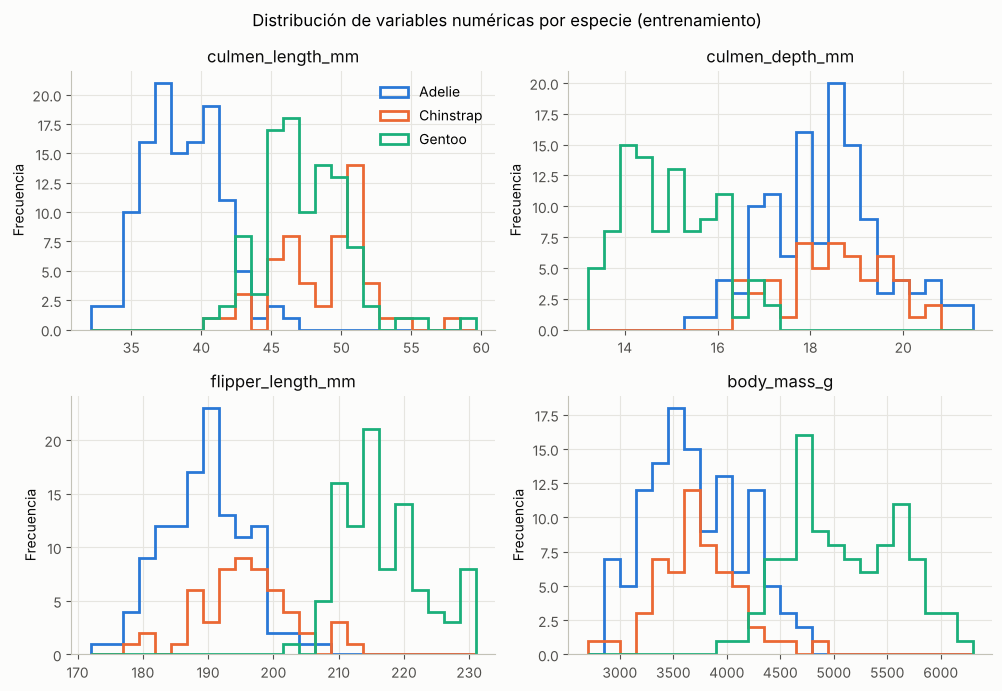

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

for ax, col in zip(axes.flat, NUMERIC):
    values = train[col].dropna()
    bins = np.linspace(values.min(), values.max(), 25)
    for sp in SPECIES:
        ax.hist(
            train.loc[train[TARGET] == sp, col].dropna(),
            bins=bins, histtype="step", linewidth=2, color=COLORS[sp], label=sp,
        )
    ax.set_title(col)
    ax.set_ylabel("Frecuencia")

axes[0, 0].legend()
fig.suptitle("Distribución de variables numéricas por especie (entrenamiento)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "explore_histograms.png")
plt.show()

#### Diagramas de caja por especie

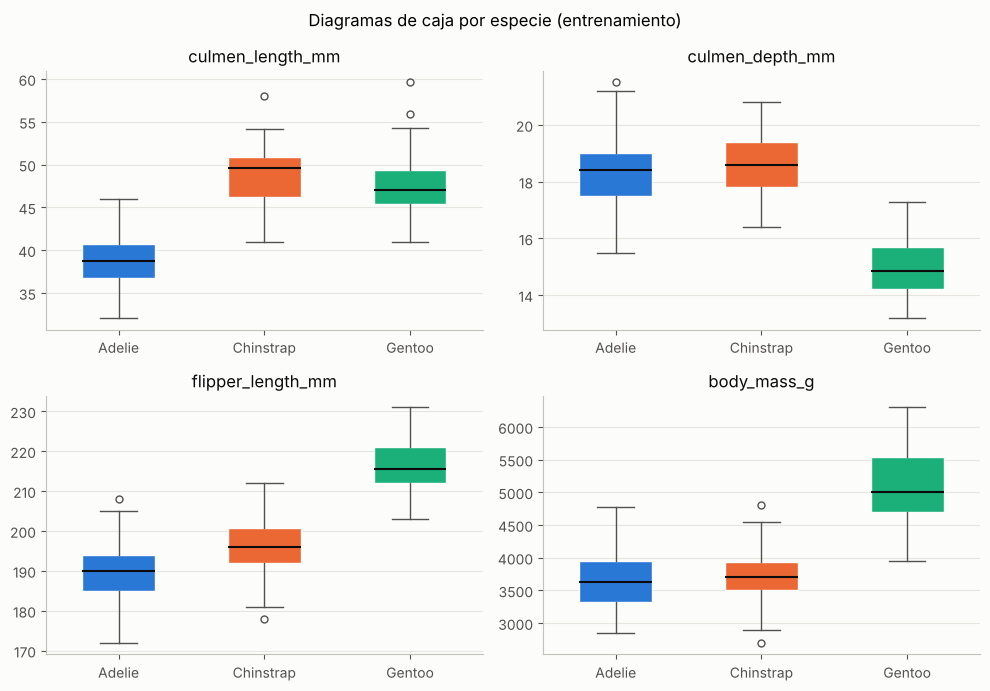

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

for ax, col in zip(axes.flat, NUMERIC):
    data = [train.loc[train[TARGET] == sp, col].dropna() for sp in SPECIES]
    bp = ax.boxplot(
        data, tick_labels=SPECIES, patch_artist=True, widths=0.5,
        medianprops={"color": "#0b0b0b", "linewidth": 1.5},
        whiskerprops={"color": "#52514e"}, capprops={"color": "#52514e"},
        flierprops={"marker": "o", "markersize": 5, "markerfacecolor": "none", "markeredgecolor": "#52514e"},
    )
    for patch, sp in zip(bp["boxes"], SPECIES):
        patch.set_facecolor(COLORS[sp])
        patch.set_edgecolor("#fcfcfb")
    ax.set_title(col)
    ax.grid(axis="x", visible=False)

fig.suptitle("Diagramas de caja por especie (entrenamiento)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "explore_boxplots.png")
plt.show()

#### Valores atípicos por especie

Valores fuera de 1.5 veces el rango intercuartílico, calculado dentro de cada especie.

In [14]:
def count_iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

train.groupby(TARGET)[NUMERIC].agg(count_iqr_outliers)

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
species,,,,
Adelie,0,1,1,0
Chinstrap,1,0,1,2
Gentoo,2,0,0,0


#### Relación entre pares de variables

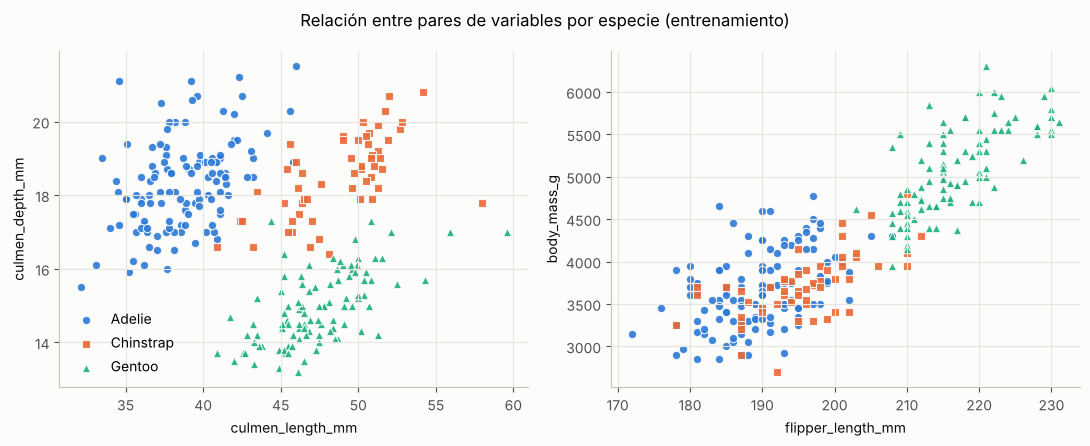

In [15]:
pairs = [
    ("culmen_length_mm", "culmen_depth_mm"),
    ("flipper_length_mm", "body_mass_g"),
]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, (x, y) in zip(axes, pairs):
    for sp in SPECIES:
        sub = train[train[TARGET] == sp]
        ax.scatter(
            sub[x], sub[y], s=36, marker=MARKERS[sp], color=COLORS[sp],
            edgecolor="#fcfcfb", linewidth=0.8, alpha=0.9, label=sp,
        )
    ax.set_xlabel(x)
    ax.set_ylabel(y)

axes[0].legend()
fig.suptitle("Relación entre pares de variables por especie (entrenamiento)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "explore_scatter.png")
plt.show()

#### Correlación entre variables numéricas

En el grupo completo y dentro de cada especie.

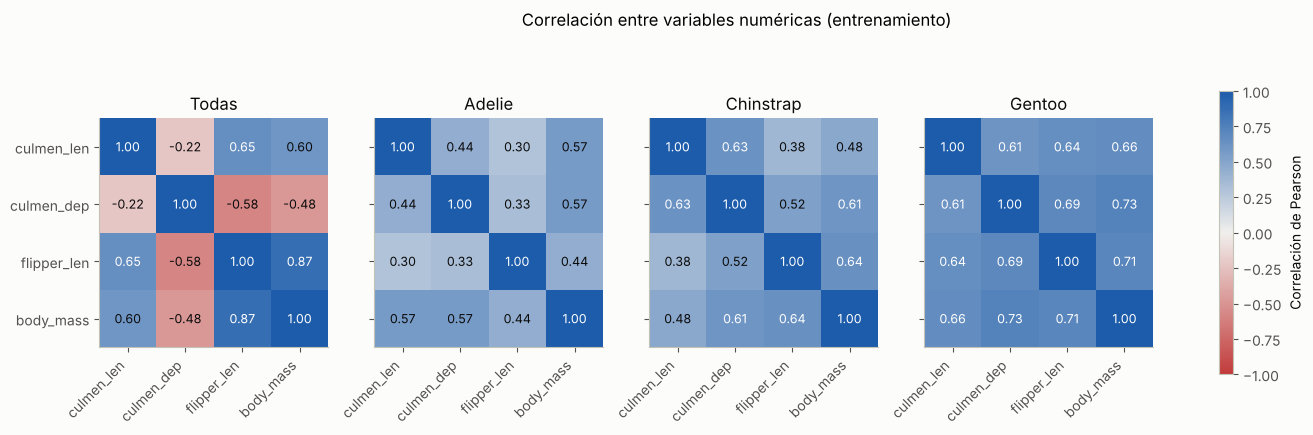

In [16]:
cmap = LinearSegmentedColormap.from_list("div", ["#c23b3b", "#f0efec", "#1c5cab"])
groups = [("Todas", train)] + [(sp, train[train[TARGET] == sp]) for sp in SPECIES]
short = ["culmen_len", "culmen_dep", "flipper_len", "body_mass"]

fig, axes = plt.subplots(1, 4, figsize=(17, 4.6))

for ax, (name, data) in zip(axes, groups):
    corr = data[NUMERIC].corr()
    im = ax.imshow(corr, cmap=cmap, vmin=-1, vmax=1)
    ax.set_xticks(range(4), short, rotation=45, ha="right")
    ax.set_yticks(range(4), short if ax is axes[0] else [])
    ax.grid(False)
    for i in range(4):
        for j in range(4):
            v = corr.iloc[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                    color="#ffffff" if abs(v) > 0.6 else "#0b0b0b", fontsize=9)
    ax.set_title(name)

fig.colorbar(im, ax=axes, shrink=0.8, label="Correlación de Pearson")
fig.suptitle("Correlación entre variables numéricas (entrenamiento)")
fig.savefig(FIGURES_DIR / "explore_correlation.png")
plt.show()

#### Guardado de resultados

In [17]:
stats.to_csv(INTERIM_DIR / "explore_stats.csv")

print(f"Guardado: {INTERIM_DIR / 'explore_stats.csv'}")
for f in sorted(FIGURES_DIR.glob("explore_*.png")):
    print(f"Guardado: {f}")

Guardado: ../data/interim/explore_stats.csv
Guardado: ../figures/explore_boxplots.png
Guardado: ../figures/explore_correlation.png
Guardado: ../figures/explore_histograms.png
Guardado: ../figures/explore_scatter.png
